In [1]:

from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))



Saving 4drtyfjtfy-1.zip to 4drtyfjtfy-1.zip
Uploaded files: ['4drtyfjtfy-1.zip']


In [2]:

import os
import zipfile

# Find the uploaded ZIP file
zip_files = [
    name for name in os.listdir("/content")
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise FileNotFoundError(
        "No ZIP file found. Please upload the dataset ZIP first."
    )

zip_path = os.path.join("/content", zip_files[0])
extract_path = "/content/weather_raw"

# Extract the dataset
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Extracted location:", extract_path)

# Display some extracted items
for root, dirs, filenames in os.walk(extract_path):
    print("\nFolder:", root)
    print("Subfolders:", dirs[:10])
    print("Files:", filenames[:10])
    if root.count(os.sep) - extract_path.count(os.sep) >= 2:
        dirs[:] = []


Dataset extracted successfully!
Extracted location: /content/weather_raw

Folder: /content/weather_raw
Subfolders: []
Files: ['dataset2.zip']


In [3]:
from pathlib import Path

dataset_path = Path("/content/weather_raw")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total images found:", len(image_paths))

for path in image_paths[:15]:
    print(path)

Total images found: 0


In [4]:

import os
import zipfile

nested_zip = "/content/weather_raw/dataset2.zip"
extract_path = "/content/weather_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(nested_zip, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Nested ZIP extracted successfully!")
print("Location:", extract_path)

for root, dirs, files in os.walk(extract_path):
    print("\nFolder:", root)
    print("Subfolders:", dirs[:10])
    print("Files:", files[:10])


Nested ZIP extracted successfully!
Location: /content/weather_dataset

Folder: /content/weather_dataset
Subfolders: ['dataset2']
Files: []

Folder: /content/weather_dataset/dataset2
Subfolders: []
Files: ['sunrise186.jpg', 'cloudy176.jpg', 'rain66.jpg', 'sunrise72.jpg', 'rain195.jpg', 'rain189.jpg', 'rain199.jpg', 'sunrise295.jpg', 'cloudy16.jpg', 'sunrise167.jpg']


In [5]:

from pathlib import Path

dataset_path = Path("/content/weather_dataset")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total images found:", len(image_paths))

for path in image_paths[:15]:
    print(path)


Total images found: 1125
/content/weather_dataset/dataset2/sunrise186.jpg
/content/weather_dataset/dataset2/cloudy176.jpg
/content/weather_dataset/dataset2/rain66.jpg
/content/weather_dataset/dataset2/sunrise72.jpg
/content/weather_dataset/dataset2/rain195.jpg
/content/weather_dataset/dataset2/rain189.jpg
/content/weather_dataset/dataset2/rain199.jpg
/content/weather_dataset/dataset2/sunrise295.jpg
/content/weather_dataset/dataset2/cloudy16.jpg
/content/weather_dataset/dataset2/sunrise167.jpg
/content/weather_dataset/dataset2/sunrise285.jpg
/content/weather_dataset/dataset2/sunrise35.jpg
/content/weather_dataset/dataset2/shine178.jpg
/content/weather_dataset/dataset2/rain72.jpg
/content/weather_dataset/dataset2/rain49.jpg


In [6]:

from pathlib import Path
from collections import Counter
import re

dataset_path = Path("/content/weather_dataset/dataset2")

classes = ["cloudy", "rain", "shine", "sunrise"]

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

def get_label(path):
    filename = path.stem.lower()

    for label in classes:
        if re.match(rf"^{label}\d*$", filename):
            return label

    return "unknown"

labels = [get_label(path) for path in image_paths]
counts = Counter(labels)

print("Total images:", len(image_paths))
print("\nImages per class:")

for label in classes:
    print(f"{label.capitalize()}: {counts[label]}")

print("Unknown images:", counts["unknown"])


Total images: 1125

Images per class:
Cloudy: 300
Rain: 215
Shine: 253
Sunrise: 357
Unknown images: 0


In [7]:

from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
import shutil
import re

# Source folder containing all images
source_dir = Path("/content/weather_dataset/dataset2")

# Destination folders
output_dir = Path("/content/weather_split")

classes = ["cloudy", "rain", "shine", "sunrise"]
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Collect image paths and labels
image_paths = [
    p for p in source_dir.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
]

def get_label(path):
    filename = path.stem.lower()

    for label in classes:
        if re.fullmatch(rf"{label}\d*", filename):
            return label

    return None

labels = [get_label(p) for p in image_paths]

# Verify every image has a recognized label
assert all(label is not None for label in labels), \
    "Some images have unrecognized labels."

# First split: 70% training, 30% remaining
train_paths, remaining_paths, train_labels, remaining_labels = (
    train_test_split(
        image_paths,
        labels,
        test_size=0.30,
        random_state=42,
        stratify=labels
    )
)

# Second split: 15% validation, 15% testing overall
val_paths, test_paths, val_labels, test_labels = (
    train_test_split(
        remaining_paths,
        remaining_labels,
        test_size=0.50,
        random_state=42,
        stratify=remaining_labels
    )
)

# Create folders and copy images
splits = {
    "train": (train_paths, train_labels),
    "val": (val_paths, val_labels),
    "test": (test_paths, test_labels)
}

for split_name, (paths, split_labels) in splits.items():
    for path, label in zip(paths, split_labels):
        destination = output_dir / split_name / label
        destination.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, destination / path.name)

print("Dataset splitting completed!")

for split_name, (paths, split_labels) in splits.items():
    print(f"\n{split_name.upper()}: {len(paths)} images")
    print(dict(Counter(split_labels)))

print("\nOutput folder:", output_dir)


Dataset splitting completed!

TRAIN: 787 images
{'cloudy': 210, 'sunrise': 250, 'shine': 177, 'rain': 150}

VAL: 169 images
{'cloudy': 45, 'rain': 32, 'shine': 38, 'sunrise': 54}

TEST: 169 images
{'sunrise': 53, 'shine': 38, 'cloudy': 45, 'rain': 33}

Output folder: /content/weather_split


Found 787 files belonging to 4 classes.
Found 169 files belonging to 4 classes.
Found 169 files belonging to 4 classes.

Weather classes: ['cloudy', 'rain', 'shine', 'sunrise']
Training batches: 50
Validation batches: 11
Testing batches: 11


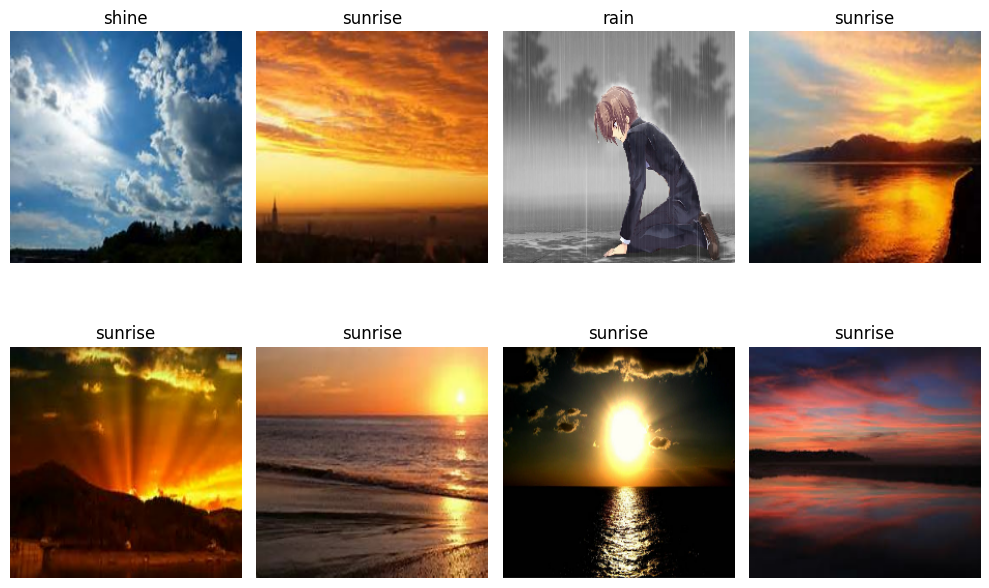

In [8]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Image settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

# Load training images
train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/weather_split/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    seed=SEED
)

# Load validation images
val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/weather_split/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Load test images
test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/weather_split/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Save the class order
class_names = train_ds.class_names

print("\nWeather classes:", class_names)
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

# Display sample images
plt.figure(figsize=(10, 7))

for images, labels in train_ds.take(1):
    for i in range(min(8, len(images))):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()


In [9]:

import tensorflow as tf

# Load MobileNetV2 with pretrained ImageNet weights
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers
base_model.trainable = False

# Build our four-class classifier
inputs = tf.keras.Input(shape=(224, 224, 3))

# Apply light data augmentation
x = tf.keras.layers.RandomFlip("horizontal")(inputs)
x = tf.keras.layers.RandomRotation(0.05)(x)

# Prepare image values for MobileNetV2
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

# Extract visual features
x = base_model(x, training=False)

# Convert features into a single vector
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = tf.keras.layers.Dropout(0.3)(x)

# Predict one of four weather classes
outputs = tf.keras.layers.Dense(
    4,
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

# Configure training
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_weather_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 50s 900ms/step - accuracy: 0.7116 - loss: 0.7462 - val_accuracy: 0.9172 - val_loss: 0.2864
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 48s 947ms/step - accuracy: 0.8831 - loss: 0.3207 - val_accuracy: 0.9290 - val_loss: 0.2150
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 83s 968ms/step - accuracy: 0.9187 - loss: 0.2291 - val_accuracy: 0.9408 - val_loss: 0.1764
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 45s 896ms/step - accuracy: 0.9479 - loss: 0.1668 - val_accuracy: 0.9408 - val_loss: 0.1636
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 83s 930ms/step - accuracy: 0.9555 - loss: 0.1356 - val_accuracy: 0.9467 - val_loss: 0.1498
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 82s 942ms/step - accuracy: 0.9708 - loss: 0.1193 - val_accuracy: 0.9408 - val_loss: 0.1565
Epoch 7/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 81s 915ms/step - accuracy: 0.9771 - loss: 0.1044 - val_accuracy: 0.9408 - val_loss: 0.1520
Epoch 8/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 83s 943ms/step - accuracy: 0.9695 - loss: 0.0983 - val_accu

In [11]:
print("Completed epochs:", len(history.epoch))
print("Last epoch number:", history.epoch[-1] + 1)

print("Best validation accuracy:",
      round(max(history.history["val_accuracy"]) * 100, 2), "%")

print("Best validation loss:",
      round(min(history.history["val_loss"]), 4))

print("Saved model exists:",
      os.path.exists("/content/best_weather_model.keras"))

Completed epochs: 9
Last epoch number: 9
Best validation accuracy: 95.27 %
Best validation loss: 0.1498
Saved model exists: True


In [12]:
import tensorflow as tf
import os

model_path = "/content/best_weather_model.keras"

if os.path.exists(model_path):
    best_model = tf.keras.models.load_model(model_path)
    print("Best model loaded successfully!")
else:
    print("Model file not found.")

test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)

print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

Best model loaded successfully!
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 705ms/step - accuracy: 0.9349 - loss: 0.1755

Test Accuracy: 93.49%
Test Loss: 0.1755


In [13]:
import numpy as np
from sklearn.metrics import classification_report

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = best_model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

11/11 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step
              precision    recall  f1-score   support

      cloudy       0.93      0.82      0.87        45
        rain       0.97      1.00      0.99        33
       shine       0.88      0.92      0.90        38
     sunrise       0.96      1.00      0.98        53

    accuracy                           0.93       169
   macro avg       0.93      0.94      0.93       169
weighted avg       0.93      0.93      0.93       169



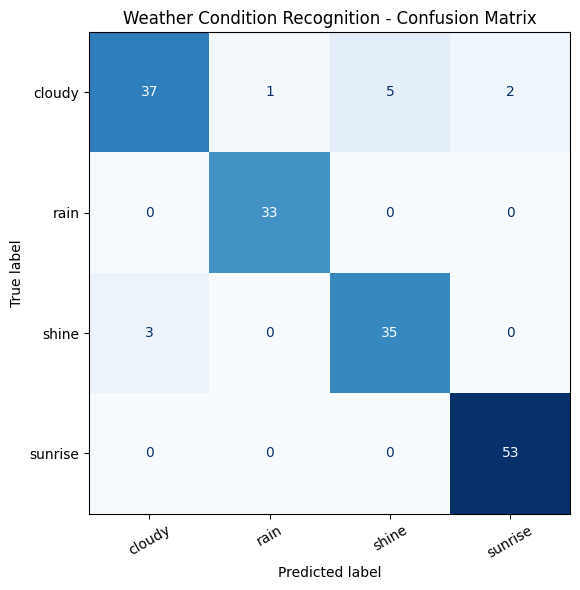

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(7, 6))
display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Weather Condition Recognition - Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()